# Membrane Swelling during Operation

This notebook investigates the amount of membrane swelling during operation

TODO: 
- [x] find method to quantify membrane swelling, ideas: ~~strike if not useful~~
    - [x] skeletonize CL and get distance as proxy for membrane thickness
    - [x] roughly limit area, where membrane can be found to guide algorithm or automatically detect outlier
    - [x] do filltering on filled space between CLs to correct for CL delamination <-- QUITE SOME ISSUE!
- [ ] save and plot results for all samples
- [ ] in part 2 (or maybe new notebook), plot membrane swelling with EC

In [1]:
# paths
import os
import socket
host = socket.gethostname()
if host == 'mpc2959.psi.ch':
    gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'
    toppath = '/mpc/homes/fische_r/NAS/DASCOELY'
    toppathSSD = '/mnt/SSD/fische_r/COELY'
    temppath = '/mnt/SSD/fische_r/tmp/joblib_tmp'
    
path_01_4D = os.path.join(toppathSSD, '01_rotated_3p1D') #h5 with rotated data
path_02_4D = os.path.join(toppathSSD, '02_registered_3p1D') #h5 with registered data

image_output = os.path.join(toppath, 'plots')
if not os.path.exists(image_output):
    os.mkdir(image_output)
image_output = os.path.join(toppath, 'plots', '04_membrane_swelling')
if not os.path.exists(image_output):
    os.mkdir(image_output)
    
scriptpath = os.path.dirname(__file__)
cwd = os.getcwd()
os.chdir(scriptpath)
git_sha = subprocess.check_output(['git', 'rev-parse', '--short', 'HEAD']).decode().strip()
githash = subprocess.check_output(['git', 'rev-parse', 'HEAD']).decode().strip()
os.chdir(cwd)
    
    
# modules
import xarray as xr
# import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1 import make_axes_locatable
# from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
# import matplotlib.font_manager as fm
# fontprops = fm.FontProperties(size=14)

import skimage
import numpy as np
from joblib import Parallel, delayed
import cupy as cp
import cucim
import scipy as sp
import scipy.ndimage

#some parameters
px = 2.75E-6 #m
vx = px**3
pxmu = 2.75 #um



In [2]:
import warnings


In [3]:
# data.close()

## Functions

In [4]:
# plt.hist(test.flatten())

In [5]:
# data.close()

In [8]:
CLth = 15000

In [9]:
def skeletonize_2D(im):
    im_skel = np.zeros(im.shape, dtype=bool)
    results = Parallel(n_jobs=16, temp_folder=temppath)(delayed(skimage.morphology.skeletonize)(im[i,:,:]) for i in range(im.shape[0]))
    for i in range(im.shape[0]):
        im_skel[i,:,:,] = results[i]
    return im_skel

In [10]:
def find_CL_2D(im2D):
    pos = np.zeros((2,im2D.shape[0]))
    for i in range(im2D.shape[0]):
        search = np.argwhere(im2D[i,:])
        if len(search) == 2:
            pos[0,i] = search[0][0]
            pos[1,i] = search[1][0]
    return pos

def find_CL_3D(im):
    results = Parallel(n_jobs=32, temp_folder=temppath)(delayed(find_CL_2D)(im[:,:,i]) for i in range(im.shape[2]))
    pos = np.zeros((results[0].shape[0], results[0].shape[1], len(results)))
    for i in range(len(results)):
        pos[:,:,i] = results[i]
    return pos

def median_warn_sup(th):
    return np.nanmedian(th, axis=1)

def get_membrane_thickness(im, i, CLth=CLth):
    warnings.filterwarnings("ignore") #ignore numpy whining and spamming nan-warnings, inside function because joblib spawns workers with default settings on warnings?!
    # im = im.copy()
    im = np.bitwise_and(im>CLth, im<40000) #second condition to filter out registration edge
    
    gpu_id = i%4 #use gpus 1 through 4, leaving the big A40 (0) alone or i%5 to use all 5
    
    with cp.cuda.Device(gpu_id):
        im = cp.array(im)
        im = cucim.skimage.morphology.binary_opening(im, footprint=cucim.skimage.morphology.ball(1.5))
        im = cp.asnumpy(im)
        mempool = cp.get_default_memory_pool()
        mempool.free_all_blocks()
        
    im = skeletonize_2D(im)
    
    pos = find_CL_3D(im)
    th = pos[1,...] - pos[0,...]
    th[th<5] = np.nan
    th[th>200] = np.nan
    median_thickness = np.nanmedian(th, axis=1)
    
    return median_thickness, pos #carry pos to see if CL buckling gives a signal

In [11]:
def results_to_pseudo_sparse(results, test):
    CLpos = np.zeros((2, test.shape[0], test.shape[2], len(results)), dtype = np.uint16)
    for i in range(len(results)):
        CLpos[...,i] = results[i][1]
    return CLpos

In [12]:
def pseudo_sparse_to_dense(im_p_sparse, shp):
    imp = im_p_sparse
    center = imp[imp>0].mean()
    center0 = center-60
    center1 = center+60
    im = np.zeros(shp, dtype=bool)
    imfilled = im.copy()
    for z in range(shp[2]):
        for x in range(shp[0]):
            y1 = imp[0,x,z]
            y2 = imp[1,x,z]
            if not np.isnan(y1):
                if y1>center0 and y1<center1: im[x, y1, z] = True
            if not np.isnan(y2):
                if y2>center0 and y2<center1: im[x, y2, z] = True   #check thi hard limits
            if not np.isnan(y1) and not np.isnan(y2) and y1>center0 and y1<center1 and y2>center0 and y2<center1:
                imfilled[x, y1:y2, z] = True
   
    return im, imfilled

def fill_CL_holes(im, radius=5):
    results = Parallel(n_jobs=32, temp_folder=temppath)(delayed(sp.ndimage.binary_fill_holes)(im[:,i,:]) for i in range(im.shape[1]))
    imfilled = np.dstack(results)
    imfilled = imfilled.transpose(0,2,1)
    return imfilled

def count_volume(im_p_sparse, shp, crops = [100, -100, 20, -20, 100, -100]):
    a,b,c,d,e,f = crops
    _ , imfilled= pseudo_sparse_to_dense(im_p_sparse, shp)
    imfilled = fill_CL_holes(imfilled)
    count = np.count_nonzero(imfilled[a:b,c:d,e:f])
    return count
            


## apply to sample

In [13]:
sample = '7x'

In [14]:
# file = '01_'+sample+'_rotated_3p1D.nc'
file = '02_'+sample+'_registered_3p1D.nc'
imagepath = os.path.join(path_02_4D, file)
data = xr.open_dataset(imagepath)
images = [im for im in data.keys() if im[3:7] == 'imag']
images.sort()

In [15]:
test = data[images[10]].data

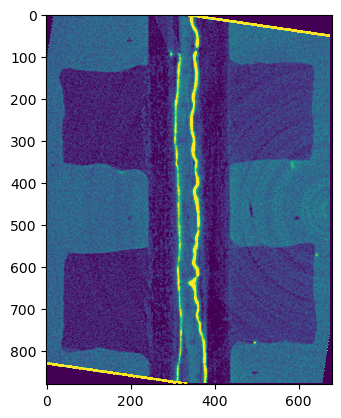

In [16]:
plt.imshow(test[:,:,200], vmin=11000, vmax = 17000)

In [17]:
# n_jobs is limited by how many jobs one GPU can take into its RAM, 16 seems ok, also 32, but might hit CPU-RAM limitations

results = Parallel(n_jobs=32, temp_folder=temppath)(delayed(get_membrane_thickness)(data[image].data, i) for (image, i) in zip(images, range(len(images))))

In [18]:
tutc = data['t_utc'].data
time = tutc - tutc.min()
time = time/60

In [19]:
attrs = data.attrs.copy()
data.close()

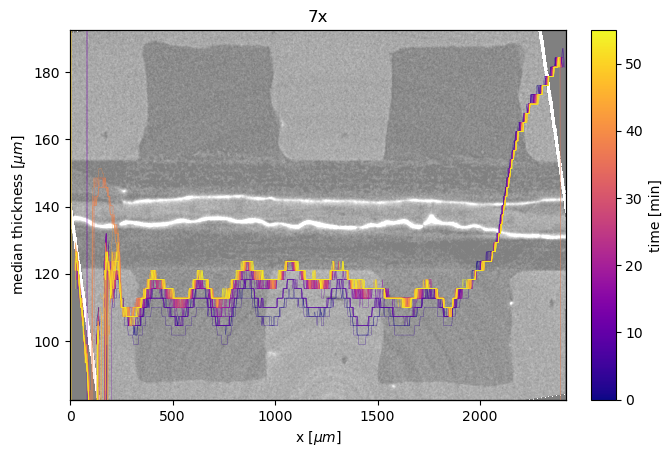

In [20]:
def px2um(x):
    return x * pxmu

def um2px(x):
    return x/pxmu

fig, ax = plt.subplots()
disp = test[:,:,200].T
ax.imshow(disp, vmin=11000, vmax = 17000, cmap = 'gray', alpha=0.5)

ax.set_xticks([])
# for minor ticks
ax.set_xticks([], minor=True)
ax.set_yticks([])
# for minor ticks
ax.set_yticks([], minor=True)

secax = ax.secondary_xaxis('bottom', functions=(px2um, um2px))
secax.set_xlabel('x [$\mu m$]')

ax2 = ax.twinx()
ax2.yaxis.set_label_position("left")
ax2.yaxis.set_ticks_position("left")

normalize = mcolors.Normalize(vmin=0, vmax=time.max())
cmap = cm.plasma

x = np.arange(disp.shape[1])*pxmu
med_th = np.zeros((len(images), len(results[0][0])))

for i in range(len(images)):
    im_plot = ax2.plot(results[i][0]*pxmu, color = cmap(normalize(time[i])), linewidth=0.2)
    med_th[i,:] = results[i][0]*pxmu

# ax.set_ylim(0, disp.shape[1])
ax2.set_ylabel('median thickness [$\mu m$]')
ax2.set_ylim(30*pxmu,70*pxmu)


axins1 = inset_axes(
    ax,
    width="5%",  # width: 50% of parent_bbox width
    height="100%",  # height: 5%
    loc='upper right',
    bbox_to_anchor=(0.1, 0., 1,1),
    bbox_transform=ax2.transAxes,
    borderpad=0,
)
# axins1.xaxis.set_ticks_position()
fig.colorbar(cm.ScalarMappable(norm=normalize, cmap=cmap), cax=axins1, label='time [min]')
ax.set_title(sample)
plt.savefig(os.path.join(image_output, sample+'_z_median_membrane_thickness.png'), dpi=1000)

In [21]:
CLpos = results_to_pseudo_sparse(results, test)

In [22]:
shp = test.shape
extract_volumes = Parallel(n_jobs=32, temp_folder=temppath)(delayed(count_volume)(CLpos[...,i], shp) for i in range(CLpos.shape[-1]))
volumes = np.array(extract_volumes)

KeyboardInterrupt: 

In [175]:
membrane_data = xr.Dataset({'z_median_thickness': (['time', 'x'], med_th), #time in minutes, x in um,thickness in um
                           'membrane volume': ('time', volumes), #volumes in px
                           't_utc': ('time', data['t_utc'].data)}, #t_utc in seconds
                          coords = {'x': x,
                                    'time': time},
                        attrs = attrs)

membrane_data['z_median_thickness'].attrs['units'] = '$\mu m$'
membrane_data['x'].attrs['units'] = '$\mu m$'
membrane_data['time'].attrs['units'] = 'min'
membrane_data['t_utc'].attrs['units'] = 's'
membrane_data.attrs['mebrane_swellig_githash'] = githash
membrane_data.attrs['mebrane_swellig_git_sha'] = git_sha
                          

In [176]:
path = os.path.join(toppath, 'processing', sample+'_membrane_swelling.nc')
membrane_data.to_netcdf(path)

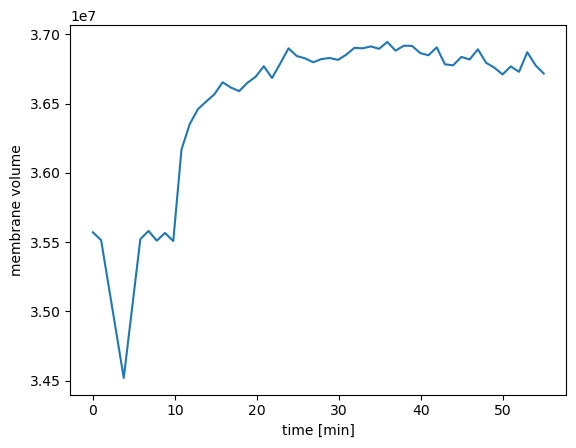

In [177]:
membrane_data['membrane volume'].plot()

In [ ]:
# i = 50
# test_file = '/mnt/SSD/fische_r/tmp/CH'+f'{i:02d}'+'.tif'
# im, imfilled = pseudo_sparse_to_dense(CLpos[...,i], shp)
# io.imsave(test_file, imfilled.astype(np.uint8)*255)

# imfilled2 = fill_CL_holes(imfilled)
# test_file = '/mnt/SSD/fische_r/tmp/CH_fill3'+f'{i:02d}'+'.tif'
# io.imsave(test_file, imfilled2.astype(np.uint8)*255)

In [36]:
# from skimage import io

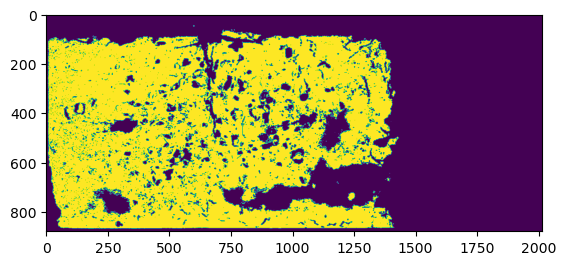

In [75]:
plt.imshow(imfilled[:,320,:])

In [138]:
volumes6 = np.array(extract_volumes)

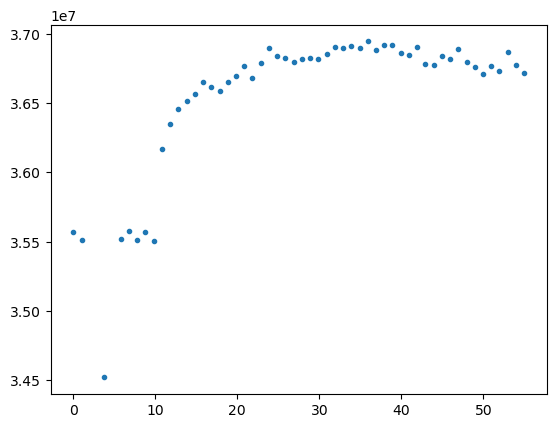

In [140]:
# plt.plot(time, volumes4, '.')
# plt.plot(time, volumes5, '.')
plt.plot(time, volumes6, '.')

In [137]:
test.shape

(880, 680, 2016)